In [19]:
# usa o pip para instalar o repositório de datasets de machine learning no colab
!pip install ucimlrepo

In [20]:
# importar as bibliotecas de manipulação de dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
# importar as bibliotecas de machine learning
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [22]:
# importar a biblioteca de datasets (repositório)
from ucimlrepo import fetch_ucirepo
# AI4I 2020
dataset = fetch_ucirepo(id=601)


In [23]:
#converte os dados lidos externamente no dataset para dataframe
df = dataset.data.features
display(df.head())

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


In [24]:
 x_data = df.select_dtypes(include=[np.number,float,int])
 display(x_data)

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,298.1,308.6,1551,42.8,0
1,298.2,308.7,1408,46.3,3
2,298.1,308.5,1498,49.4,5
3,298.2,308.6,1433,39.5,7
4,298.2,308.7,1408,40.0,9
...,...,...,...,...,...
9995,298.8,308.4,1604,29.5,14
9996,298.9,308.4,1632,31.8,17
9997,299.0,308.6,1645,33.4,22
9998,299.0,308.7,1408,48.5,25


In [25]:
# escalona os dados para que o modelo não apresente falha de inferência
scaler = StandardScaler()
x_data_scaled = scaler.fit_transform(x_data)

In [26]:
values = []
k_values = range(1,11)

print("Calculando o k ideal com o Método do Cotovelo:")
for k in k_values:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(x_data_scaled)
  values.append(kmeans.inertia_)

Calculando o k ideal com o Método do Cotovelo:


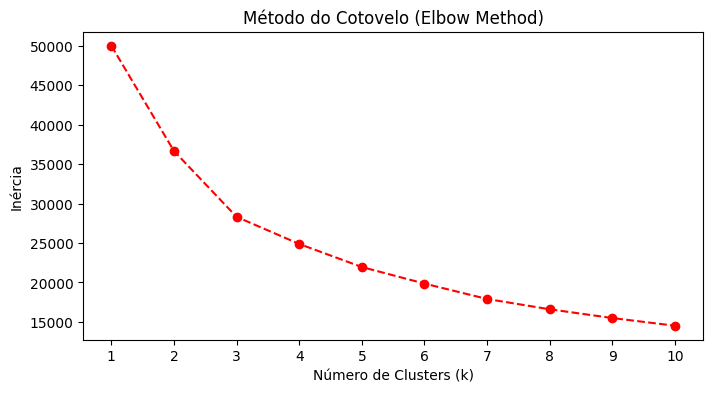

In [27]:
plt.figure(figsize=(8,4))
plt.plot(k_values, values, marker='o', linestyle='--', color='red')
plt.title('Método do Cotovelo (Elbow Method)')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia')
plt.xticks(k_values)
plt.show()

In [29]:
# define qual o k a ser usado baseado no método do cotovelo, e cria novamente o modelo
k_used = 3
model = KMeans(n_clusters=k_used, random_state=42, n_init=10)

groups = model.fit_predict(x_data_scaled)
print(f'Grupos criados: {groups}')
df['Group'] = groups
display(df.head())

Grupos criados: [1 1 1 ... 1 1 1]


/tmp/ipykernel_8277/4174047237.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Group'] = groups


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Group
0,M,298.1,308.6,1551,42.8,0,1
1,L,298.2,308.7,1408,46.3,3,1
2,L,298.1,308.5,1498,49.4,5,1
3,L,298.2,308.6,1433,39.5,7,1
4,L,298.2,308.7,1408,40.0,9,1


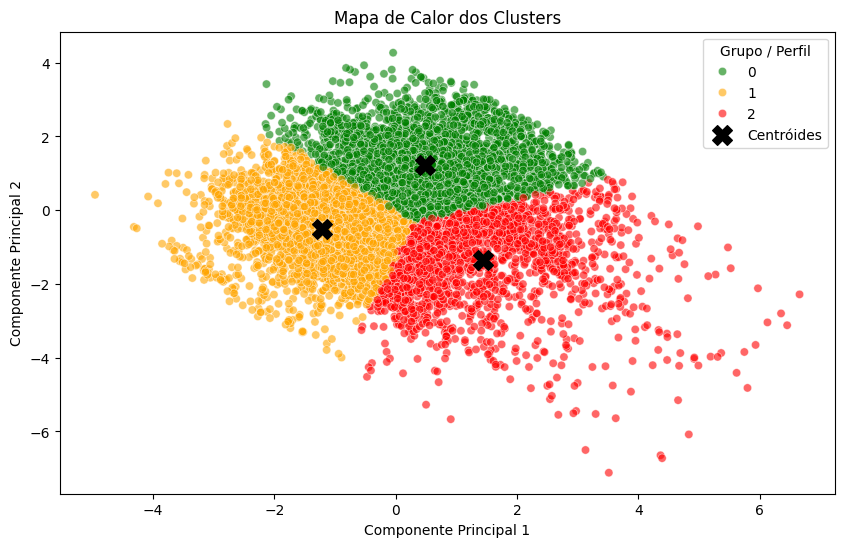

In [30]:

pca = PCA(n_components=2)
x_2d = pca.fit_transform(x_data_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=x_2d[:,0], y=x_2d[:,1], hue=df['Group'],
                palette=['green','orange','red'],alpha=0.6)
points_2d = pca.transform(model.cluster_centers_)
plt.scatter(points_2d[:,0], points_2d[:,1], c='black', marker='X', s=200, label='Centróides')
plt.title('Mapa de Calor dos Clusters')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(title='Grupo / Perfil')
plt.show()



In [31]:
score = silhouette_score(x_data_scaled, groups)
print(f'Score de Silhueta: {score}')

Score de Silhueta: 0.262210380484853
